# Phase 2: Preprocessing Pipeline & Verification

**Project:** Agentic Predictive Maintenance  
**Dataset:** NASA C-MAPSS FD001 (Single Operating Condition, Single Fault Mode)  
**Objective:** Transform raw sensor telemetry into structured sliding-window temporal sequences for deep learning sequence models (e.g., LSTM, GRU, Transformers) with zero data leakage.

---
### Pipeline Stages:
1. **Feature Screening:** Drop 10 confirmed uninformative/zero-variance columns.
2. **Piecewise-Linear RUL Capping:** Compute linear RUL and apply upper cap at $RUL = 125$ cycles.
3. **MinMax Feature Scaling:** Normalize 14 retained sensors to range $[0, 1]$ fit solely on training data.
4. **Sliding-Window Sequence Generation:** Generate $(X, y)$ sequence pairs (window length $= 30$).
5. **Test Set Final-Window Extraction:** Extract final $30$-cycle evaluation sequence for each test engine.
6. **Artifact Persistence:** Persist numpy arrays to `data/processed/` and scaler to `outputs/scaler.pkl`.


In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Add project root to path
PROJECT_ROOT = Path("..").resolve() if Path("..").resolve().name == "predictive-maintenance" else Path(".").resolve()
sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_cmapss
from src.preprocessing import (
    drop_uninformative_columns,
    compute_rul,
    scale_features,
    generate_sequences,
    get_test_sequences,
    count_padded_engines,
    UNINFORMATIVE_COLUMNS,
    RETAINED_SENSOR_COLUMNS,
)

# Visual styling
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.dpi"] = 120

OUTPUT_DIR = PROJECT_ROOT / "outputs" / "eda_plots"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

print("Environment and preprocessing modules loaded.")


Environment and preprocessing modules loaded.


## 1. Raw Data Ingestion
Loading raw C-MAPSS FD001 dataset via `load_cmapss()`.

In [2]:
train_raw, test_raw, rul_df = load_cmapss(subset="FD001", data_dir=PROJECT_ROOT / "data" / "raw")

print(f"Raw Train Shape: {train_raw.shape} (Engines: {train_raw['unit_number'].nunique()})")
print(f"Raw Test Shape:  {test_raw.shape} (Engines: {test_raw['unit_number'].nunique()})")
print(f"Test Ground Truth RUL: {rul_df.shape}")


Raw Train Shape: (20631, 26) (Engines: 100)
Raw Test Shape:  (13096, 26) (Engines: 100)
Test Ground Truth RUL: (100, 2)


## 2. Feature Screening: Dropping Uninformative Columns
Dropping 10 uninformative/constant features identified during Phase 1 EDA:
* 3 Operational Settings: `operational_setting_1`, `operational_setting_2`, `operational_setting_3`
* 7 Constant/Near-Constant Sensors: `sensor_measurement_1`, `5`, `6`, `10`, `16`, `18`, `19`

Retaining **14 informative sensor measurements**: `2, 3, 4, 7, 8, 9, 11, 12, 13, 14, 15, 17, 20, 21`.

In [3]:
train_dropped = drop_uninformative_columns(train_raw)
test_dropped = drop_uninformative_columns(test_raw)

print(f"Train Shape after dropping: {train_dropped.shape}")
print(f"Test Shape after dropping:  {test_dropped.shape}")
print(f"Retained Sensor Columns ({len(RETAINED_SENSOR_COLUMNS)}):")
print(RETAINED_SENSOR_COLUMNS)


Train Shape after dropping: (20631, 16)
Test Shape after dropping:  (13096, 16)
Retained Sensor Columns (14):
['sensor_measurement_2', 'sensor_measurement_3', 'sensor_measurement_4', 'sensor_measurement_7', 'sensor_measurement_8', 'sensor_measurement_9', 'sensor_measurement_11', 'sensor_measurement_12', 'sensor_measurement_13', 'sensor_measurement_14', 'sensor_measurement_15', 'sensor_measurement_17', 'sensor_measurement_20', 'sensor_measurement_21']


## 3. Ground-Truth RUL & Piecewise-Linear Capping
For each run-to-failure engine, linear RUL is computed as:
$$\text{RUL}(t) = t_{\text{max}} - t$$
In standard prognostic literature for C-MAPSS FD001, early operational cycles exhibit negligible physical degradation. An upper threshold of **$125$ cycles** is applied:
$$\text{RUL}_{\text{capped}}(t) = \min(\text{RUL}(t), 125)$$

In [4]:
train_rul = compute_rul(train_dropped, max_rul=125, is_train=True)

print(f"Raw RUL Range:    [{train_rul['RUL'].min()}, {train_rul['RUL'].max()}] cycles")
print(f"Capped RUL Range: [{train_rul['RUL_capped'].min()}, {train_rul['RUL_capped'].max()}] cycles")
print(f"Rows with Capped Value (=125): {(train_rul['RUL_capped'] == 125).sum():,} / {len(train_rul):,} ({(train_rul['RUL_capped'] == 125).mean()*100:.1f}%)")

train_rul[["unit_number", "time_in_cycles", "RUL", "RUL_capped"]].head(10)


Raw RUL Range:    [0, 361] cycles
Capped RUL Range: [0, 125] cycles
Rows with Capped Value (=125): 8,131 / 20,631 (39.4%)


,unit_number,time_in_cycles,RUL,RUL_capped
0,1,1,191,125
1,1,2,190,125
2,1,3,189,125
3,1,4,188,125
4,1,5,187,125
5,1,6,186,125
6,1,7,185,125
7,1,8,184,125
8,1,9,183,125
9,1,10,182,125


### Visual Verification of Piecewise Capping
Overlaying raw linear RUL vs capped RUL for 3 sample engines spanning minimum, typical, and maximum lifetimes.

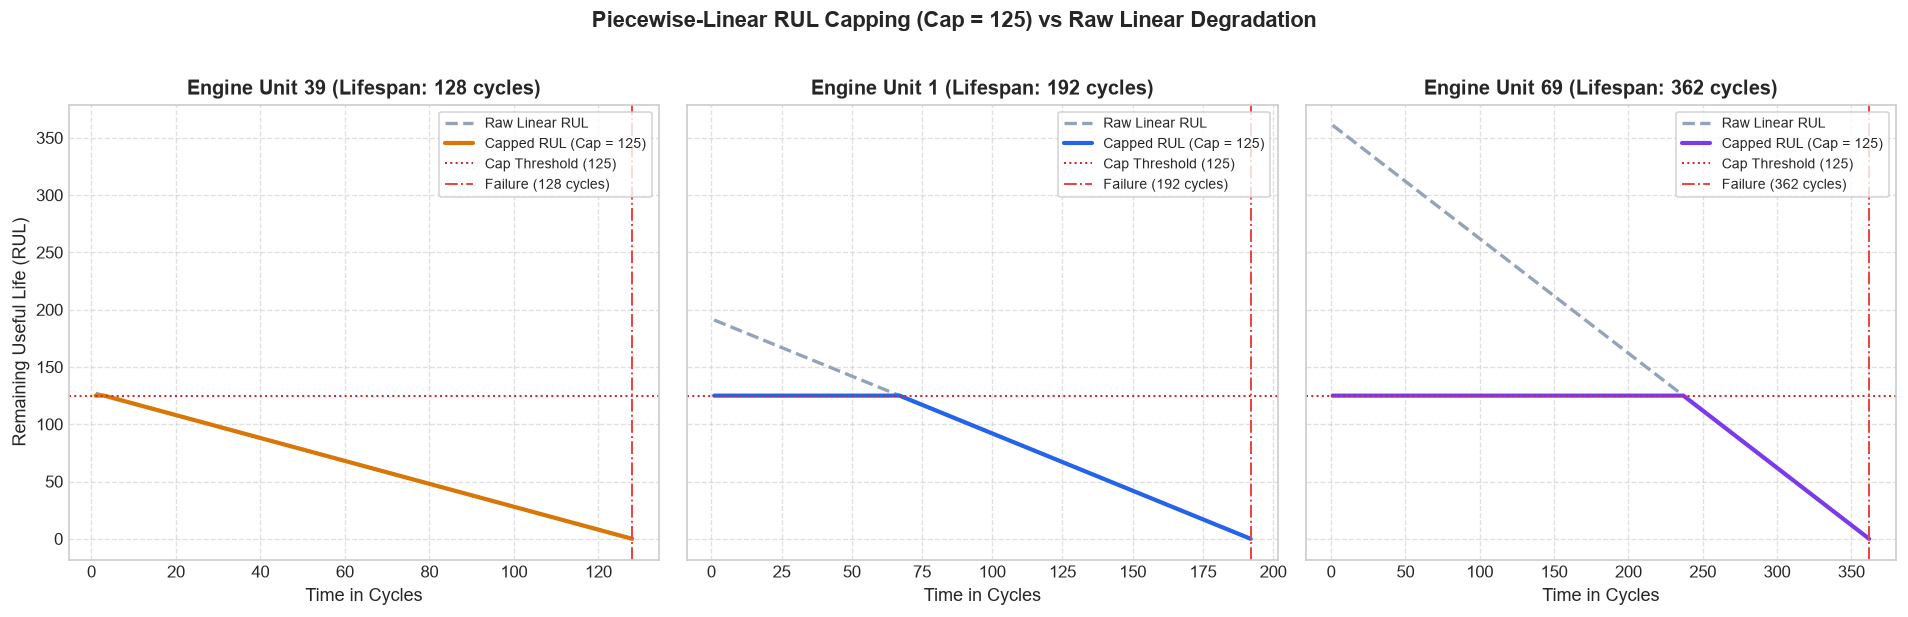

In [5]:
sample_units = [39, 1, 69]  # Min life (39: 128), Typical (1: 192), Max life (69: 362)
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
colors = ["#d97706", "#2563eb", "#7c3aed"]

for idx, unit_id in enumerate(sample_units):
    ax = axes[idx]
    unit_df = train_rul[train_rul["unit_number"] == unit_id]
    
    ax.plot(
        unit_df["time_in_cycles"],
        unit_df["RUL"],
        label="Raw Linear RUL",
        color="#94a3b8",
        linestyle="--",
        linewidth=2.0,
    )
    ax.plot(
        unit_df["time_in_cycles"],
        unit_df["RUL_capped"],
        label="Capped RUL (Cap = 125)",
        color=colors[idx],
        linewidth=2.5,
    )
    ax.axhline(125, color="#dc2626", linestyle=":", linewidth=1.2, label="Cap Threshold (125)")
    ax.axvline(unit_df["time_in_cycles"].max(), color="#ef4444", linestyle="-.", linewidth=1.2, label=f"Failure ({unit_df['time_in_cycles'].max()} cycles)")
    
    ax.set_title(f"Engine Unit {unit_id} (Lifespan: {len(unit_df)} cycles)", fontsize=12, fontweight="bold")
    ax.set_xlabel("Time in Cycles", fontsize=11)
    if idx == 0:
        ax.set_ylabel("Remaining Useful Life (RUL)", fontsize=11)
    ax.legend(loc="upper right", fontsize=8.5, frameon=True, facecolor="white")
    ax.grid(True, linestyle="--", alpha=0.6)

plt.suptitle("Piecewise-Linear RUL Capping (Cap = 125) vs Raw Linear Degradation", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "07_rul_capping_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


## 4. MinMax Feature Scaling (Zero Leakage)
A `MinMaxScaler(range=(0, 1))` is fit strictly on training features and subsequently used to transform both train and test sets. The fitted scaler is persisted to `outputs/scaler.pkl`.

In [6]:
train_scaled, test_scaled, scaler = scale_features(
    train_rul,
    test_dropped,
    feature_cols=RETAINED_SENSOR_COLUMNS,
    scaler_path=PROJECT_ROOT / "outputs" / "scaler.pkl",
)

print(f"Scaler saved to: {PROJECT_ROOT / 'outputs' / 'scaler.pkl'}")
print(f"Train Scaled Min: {train_scaled[RETAINED_SENSOR_COLUMNS].min().min():.4f}, Max: {train_scaled[RETAINED_SENSOR_COLUMNS].max().max():.4f}")
print(f"Test Scaled Min:  {test_scaled[RETAINED_SENSOR_COLUMNS].min().min():.4f}, Max: {test_scaled[RETAINED_SENSOR_COLUMNS].max().max():.4f}")


Scaler saved to: C:\Users\naiky\OneDrive\Desktop\Projects\predictive-maintenance\outputs\scaler.pkl
Train Scaled Min: 0.0000, Max: 1.0000
Test Scaled Min:  -0.0436, Max: 1.0810


## 5. Temporal Sequence Generation (Sliding Window = 30)
* **Training Sequences:** A sliding window of $30$ cycles slides over each engine's trajectory to create $(X, y)$ pairs, where $X \in \mathbb{R}^{30 \times 14}$ and $y = \text{RUL}_{\text{capped}}$ at the window's final cycle.
* **Test Sequences:** Exactly one $30$-cycle sequence is generated per test engine (the final $30$ observed cycles) for direct evaluation against `RUL_FD001.txt`.
* **Padding Check:** Any engine with total cycles $< 30$ is left-padded with its initial cycle repeated.

In [7]:
SEQUENCE_LENGTH = 30

train_padded = count_padded_engines(train_scaled, sequence_length=SEQUENCE_LENGTH)
test_padded = count_padded_engines(test_scaled, sequence_length=SEQUENCE_LENGTH)

print(f"Training Engines requiring Left-Padding: {train_padded} / 100")
print(f"Test Engines requiring Left-Padding:     {test_padded} / 100")

# Generate Training Sequences
X_train, y_train = generate_sequences(
    train_scaled,
    sequence_length=SEQUENCE_LENGTH,
    feature_cols=RETAINED_SENSOR_COLUMNS,
    label_col="RUL_capped",
)

# Generate Test Sequences
X_test, test_unit_order = get_test_sequences(
    test_scaled,
    sequence_length=SEQUENCE_LENGTH,
    feature_cols=RETAINED_SENSOR_COLUMNS,
)

y_test = rul_df["RUL"].values.astype(np.float32)
y_test_capped = np.minimum(y_test, 125.0).astype(np.float32)

print(f"\nFinal Processed Array Shapes:")
print(f"  X_train: {X_train.shape} (dtype: {X_train.dtype})")
print(f"  y_train: {y_train.shape} (dtype: {y_train.dtype})")
print(f"  X_test:  {X_test.shape} (dtype: {X_test.dtype})")
print(f"  y_test:  {y_test.shape} (dtype: {y_test.dtype})")
print(f"  Test unit IDs: {test_unit_order[:5]} ... {test_unit_order[-5:]}")


Training Engines requiring Left-Padding: 0 / 100
Test Engines requiring Left-Padding:     0 / 100

Final Processed Array Shapes:
  X_train: (17731, 30, 14) (dtype: float32)
  y_train: (17731,) (dtype: float32)
  X_test:  (100, 30, 14) (dtype: float32)
  y_test:  (100,) (dtype: float32)
  Test unit IDs: [1 2 3 4 5] ... [ 96  97  98  99 100]


## 6. Persisting Preprocessed Datasets
Saving arrays to `data/processed/` for direct consumption by deep learning models in Phase 3.

In [8]:
np.save(PROCESSED_DIR / "X_train.npy", X_train)
np.save(PROCESSED_DIR / "y_train.npy", y_train)
np.save(PROCESSED_DIR / "X_test.npy", X_test)
np.save(PROCESSED_DIR / "y_test.npy", y_test)
np.save(PROCESSED_DIR / "y_test_capped.npy", y_test_capped)
np.save(PROCESSED_DIR / "test_unit_order.npy", test_unit_order)

print("Saved all preprocessed numpy arrays to data/processed/:")
for p in sorted(PROCESSED_DIR.glob("*.npy")):
    size_kb = p.stat().st_size / 1024
    print(f"  - {p.name:<22} ({size_kb:>8.2f} KB)")


Saved all preprocessed numpy arrays to data/processed/:
  - test_unit_order.npy    (    0.91 KB)
  - X_test.npy             (  164.19 KB)
  - X_train.npy            (29090.05 KB)
  - y_test.npy             (    0.52 KB)
  - y_test_capped.npy      (    0.52 KB)
  - y_train.npy            (   69.39 KB)
